In [36]:
import os
import sys
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


import warnings
warnings.filterwarnings("ignore")
logging.getLogger('fontTools').setLevel(logging.ERROR)

sns.set_context('notebook')
pd.set_option('float_format', '{:.3f}'.format)
pd.set_option('display.width', 200)

plt.rcParams.update({'font.family': 'serif',
                     'mathtext.fontset': 'cm',
                     'pdf.fonttype': 42})

path = '/Users/vladislav/Downloads/'
sys.path.append(path)
from rink import plot_rink

os.makedirs('exam_figures', exist_ok=True)

def save_figure(name):
    plt.savefig('exam_figures/' + name + '.pdf', bbox_inches='tight')
    plt.savefig('exam_figures/' + name + '.svg', bbox_inches='tight')

**Пункт 1.** Первый столбец это - номер строки, поэтому это как индекс. Тогда получается  38 столбцов.

In [37]:
events = pd.read_excel(path + 'NHL-playoffs-2026.xlsx', index_col=0)

print(events.shape)
print(events.iloc[:10, [2, 3, 4, 9, 12]])

(29710, 38)
         Date      Away Team       Home Team Remaining Time     Play Type
0  2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1  2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2  2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3  2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4  2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5  2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6  2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7  2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8  2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9  2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot


**Пункт 2.** Последняя запись каждой игры это `game-end`, в ней уже накоплен итоговый счет, я решил взять счет оттуда. Количество овертаймов это номер последнего периода минус три: один овертайм дает `Final/OT`, два дают `Final/2OT` и т.д.

Игры и команды нужно взять из первой записи игры, они не меняются.

In [38]:
by_game = events.groupby('Game ID')
last = by_game.tail(1).set_index('Game ID')

games = by_game[['Date', 'Away Team', 'Home Team']].first()
games['Away Score'] = last['Cumulated Away Score']
games['Home Score'] = last['Cumulated Home Score']

overtimes = by_game['Period'].max() - 3
games['Outcome'] = overtimes.map(lambda n: 'Final' if n == 0 else 'Final/' + ('' if n == 1 else str(n)) + 'OT')

print(games.columns)
print(games.iloc[-5:, -4:])

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='str')
                       Home Team  Away Score  Home Score    Outcome
Game ID                                                            
2025030412   Carolina Hurricanes           3           4   Final/OT
2025030413  Vegas Golden Knights           4           5  Final/2OT
2025030414  Vegas Golden Knights           5           3      Final
2025030415   Carolina Hurricanes           2           4      Final
2025030416  Vegas Golden Knights           3           0      Final


**Пункт 3**

In [39]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return '%s - %s (%d - %d, %s, %s)' % (g['Home Team'], g['Away Team'], g['Home Score'], g['Away Score'],
                                           g['Outcome'], g['Date'])


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


**Пункт 4**

In [40]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64

**Пункт 5** 

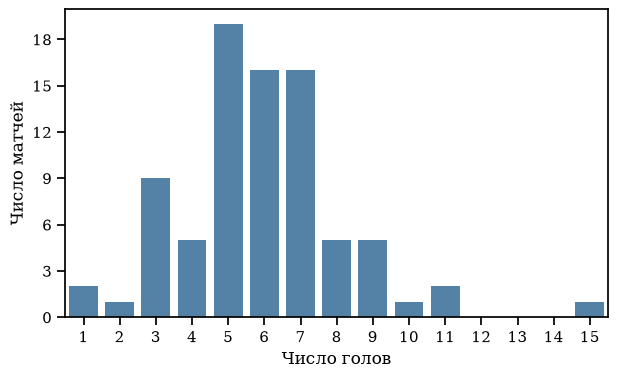

In [41]:
plt.figure(figsize=(7, 4))
sns.countplot(data=games, x='Total Score', order=range(1, games['Total Score'].max() + 1), color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.yticks(range(0, 20, 3))
save_figure('goals_hist')
plt.show()

Распределение выглядит как колокол с центром на 5-7 голах: чаще всего в матче забивали 5 шайб (19 матчей), затем по 16 матчей с 6 и 7 голами. Среднее - 5,9, медиана - 6, на 4-8 голов приходится 74% матчей, дисперсия - 5,1. Матчей с одним-двумя голами всего три, поэтому левый хвост короткий, а правый - длиннее, так как с десятью и более голами - четыре матча, а рекорд 15

**Пункт 6**

In [42]:
total = games['Total Score']

print('Самые нерезультативные игры:')
print([gameInfo(i) for i in games.index[total == total.min()]])
print()
print('Самые результативные игры:')
print([gameInfo(i) for i in games.index[total == total.max()]])

Самые нерезультативные игры:
['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

Самые результативные игры:
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


**Пункт 7.** Длинная таблица, вратарь уже записан среди шести игроков на льду, поэтому после удаления повторов он считается один раз

In [43]:
away_cols = ["Away Team's Player on the Ice #%d" % i for i in range(1, 7)] + ["Away Team's Goalie"]
home_cols = ["Home Team's Player on the Ice #%d" % i for i in range(1, 7)] + ["Home Team's Goalie"]

players = (events.melt(id_vars='Game ID', value_vars=away_cols + home_cols, value_name='Player')
                 .dropna(subset=['Player'])
                 .drop_duplicates(['Game ID', 'Player']))

player_count = players.groupby('Game ID').size().rename('Player Count')

counts = pd.DataFrame({'Game Info': [gameInfo(i) for i in player_count.index], 'Player Count': player_count},
                      index=player_count.index)
print(counts[counts['Player Count'] == counts['Player Count'].max()])
print()
print(counts['Player Count'].describe())

                                                    Game Info  Player Count
Game ID                                                                    
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...            40

count   82.000
mean    38.122
std      0.365
min     38.000
25%     38.000
50%     38.000
75%     38.000
max     40.000
Name: Player Count, dtype: float64


40 игроков было в матче Монреаль - Буффало. Обычно в игре участвует 38 человек, но в этом матче на лед выходили четыре вратаря вместо двух, то есть игроков больше на два

**Пункт 8.** Для каждого броска надо понять, в какие ворота он летит. Хозяева атакуют правые ворота (X = 89), если они защищают левые (Home Team's Defending Side == 'left'), и левые (X = -89), если защищают правые. У гостей наоборот. Логически если «бросает хозяин» и «хозяин защищает левые» либо оба условия ложны, то бьют в X = 89, иначе в X = -89.

Формулу из задания я записал так: по x расстояние через модуль разности, то есть |x - X|, по y расстояние до створа - это max(|y| - 3, 0) (ноль, если бросок с «коридора» между штангами), а итоговое расстояние это длина гипотенузы.

In [44]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(shot_types)

def goal_x(df):
    home_shot = df['Team Making the Play'] == df['Home Team']
    defends_left = df["Home Team's Defending Side"] == 'left'
    return np.where(home_shot == defends_left, 89, -89)

def shot_length(x, y, X):
    return np.hypot(np.abs(x - X), np.clip(np.abs(y) - 3, 0, None))


events['Shot Length'] = np.where(is_shot,
                                 shot_length(events['X Coordinate on the Ice Rink'],
                                             events['Y Coordinate on the Ice Rink'],
                                             goal_x(events)),
                                 np.nan)

events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


**Пункт 9.** В этом задании нужно сравнивать распределения, а не количества, так как у точных бросков (`shot-on-goal` и `goal`) наблюдений почти в два раза больше, чем у неточных. Поэтому в `displot()` нужно посчитать долю (`stat='density'`) и нормировать каждую группу отдельно (`common_norm=False`), тогда площадь под каждой гистограммой будет равна единице.

Shot
on goal    4623
missed     2643
Name: count, dtype: int64


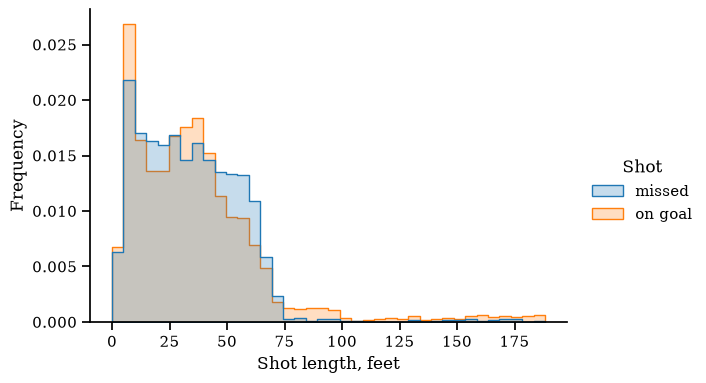

In [45]:
shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')
print(shots['Shot'].value_counts())

sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
            stat='density', common_norm=False, binwidth=5, element='step', height=4, aspect=1.5)
plt.xlabel('Shot length, feet')
plt.ylabel('Frequency')
save_figure('shot_length_hist')
plt.show()

In [46]:
print(shots.groupby('Shot')['Shot Length'].describe())
print()
print('Доля бросков дальше 100 футов:')
print(shots.groupby('Shot')['Shot Length'].apply(lambda s: (s > 100).mean()))

           count   mean    std   min    25%    50%    75%     max
Shot                                                             
missed  2643.000 34.014 22.313 0.000 16.155 32.249 49.041 185.068
on goal 4623.000 36.207 29.997 0.000 15.000 31.828 47.011 188.215

Доля бросков дальше 100 футов:
Shot
missed    0.009
on goal   0.035
Name: Shot Length, dtype: float64


**Пункт 10.** Блокированные броски исключвем, потому что в `shots` их уже нет. Среди остальных точные - это `shot-on-goal` и `goal`, а неточные - `missed-shot`. Среднее значение булевой колонки как раз дает долю.

In [47]:
shots['On Goal'] = shots['Play Type'] != 'missed-shot'

numshots = shots.groupby(['Game ID', 'Team Making the Play'])[['On Goal']].mean()
numshots.columns = ['Share of Shots on Goal']

print(numshots['Share of Shots on Goal'])
print()
print(numshots['Share of Shots on Goal'].describe())
print()
sizes = shots.groupby(['Game ID', 'Team Making the Play']).size()
print('Незаблокированных бросков за игру у команды:')
print(sizes.describe())

p = shots['On Goal'].mean()
print()
print('Если бы каждый бросок независимо шел в створ с вероятностью %.3f, то разброс доли был бы около %.3f' % (
    p, np.sqrt(p * (1 - p) / sizes.mean())))

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64

Незаблокированных бросков за игру у команды:
count   164.000
mean     44.305
std      10.651
min      18.000
25%      37.000
50%      43.000
75%      51.000
max      83.000
dtype: float64

Если бы каждый бросок независимо шел в створ с вероятностью 0.636, то разброс доли был бы окол

В среднем 63,9% незаблокированных бросков команда отправляет в створ. От игры к игре доля сильно скачет: от 35% до 86%, стандартное отклонение 8,5 процентных пункта. Но и бросков в одной игре у команды немного, около от 18 до 83. Если бы каждый бросок независимо шел в створ с вероятностью 0,64, разброс при 44 бросках был бы около 7 пунктов, то есть почти такой же, как наблюдаемый. Получается, что точность бросков в отдельно взятой игре - это в основном дело случая, а не того, что команда «в этот день стреляла лучше или хуже».

**Пункт 11.** Тут нужно усреднить долю по играм каждой команды и заодно можно узнать, сколько игр сыграла каждая команда, потому что у тех, кто вылетел в первом раунде, игр всего 4-6.

In [48]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()

print(avgnumshots.nlargest(5))
print()
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64

Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64


In [49]:
games_played = pd.concat([games['Home Team'], games['Away Team']]).value_counts()
games_played.name = 'Games'
print(games_played.to_string())

Vegas Golden Knights    22
Montréal Canadiens      19
Carolina Hurricanes     19
Buffalo Sabres          13
Colorado Avalanche      13
Anaheim Ducks           12
Minnesota Wild          11
Philadelphia Flyers     10
Tampa Bay Lightning      7
Boston Bruins            6
Pittsburgh Penguins      6
Dallas Stars             6
Utah Mammoth             6
Edmonton Oilers          6
Ottawa Senators          4
Los Angeles Kings        4


Лидеры: Эдмонтон (70,6%), Филадельфия (68,4%), Даллас, Миннесота, Колорадо (65,3%). В хвосте: Питтсбург (55,4%), Юта (59,9%), Каролина, Тампа и Баффало (62,6%). Размах между первым и последним 15 пунктов, но верить в эти различия осторожно: Эдмонтон, Даллас, Питтсбург, Юта и Бостон сыграли всего по 6 игр. Стандартная ошибка среднего по шести играм 0,085/√6, то есть около 3,5 пункта, и отличие Эдмонтона от лиги (63,9%) это примерно две ошибки, а Питтсбурга (-8,5 пункта) примерно 2,4. У Каролины, сыгравшей 19 игр, отставание от среднего 2,4 пункта при ошибке около 2 пунктов, то есть это обычный шум. Значит, содержательно команды по точности бросков практически не отличаются, а Питтсбург - единственная команда, у которой отличие похоже на настоящее

**Пункт 12.** Точными будем считать те же броски, что и раньше, то есть `shot-on-goal` вместе с `goal` (гол это тоже бросок в створ). Для каждой пары «игра, команда» считаем число бросков в створ и голов, потом усредняем по играм команды.

In [50]:
per_game = pd.DataFrame({'Shot': events['Play Type'].isin(['shot-on-goal', 'goal']),
                         'Goal': events['Play Type'] == 'goal'}).groupby(
    [events['Game ID'], events['Team Making the Play']]).sum()

avgshots = per_game.groupby('Team Making the Play').mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


**Пункт 13.** Я не стал подписывать все команды, чтобы график был читаемым, сделал шесть, которые сильнее всего отклонились

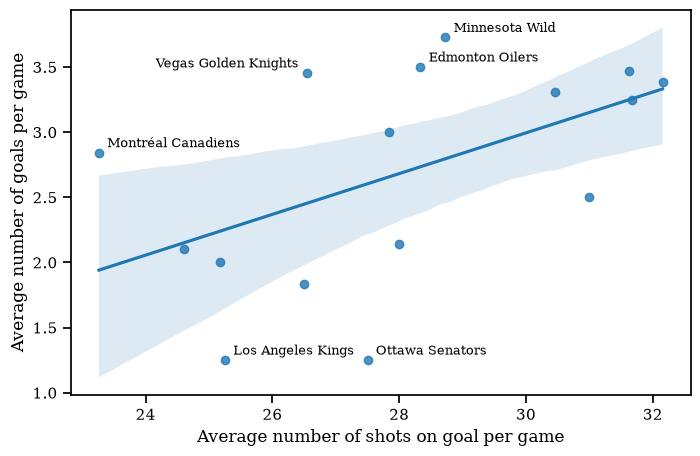

Наклон: 0.156  Константа: -1.698  Корреляция: 0.521  p-value: 0.039

Team Making the Play
Ottawa Senators        -1.350
Los Angeles Kings      -1.000
Dallas Stars           -0.650
Pittsburgh Penguins    -0.610
Tampa Bay Lightning    -0.540
Boston Bruins          -0.240
Philadelphia Flyers    -0.050
Anaheim Ducks          -0.010
Colorado Avalanche      0.050
Carolina Hurricanes     0.220
Buffalo Sabres          0.240
Utah Mammoth            0.340
Edmonton Oilers         0.770
Montréal Canadiens      0.900
Minnesota Wild          0.930
Vegas Golden Knights    1.000


In [51]:
slope, intercept = np.polyfit(avgshots['Shot'], avgshots['Goal'], 1)
r, p = stats.pearsonr(avgshots['Shot'], avgshots['Goal'])
residual = avgshots['Goal'] - (intercept + slope * avgshots['Shot'])
labelled = residual.abs().nlargest(6).index

plt.figure(figsize=(8, 5))
sns.regplot(data=avgshots, x='Shot', y='Goal')
for team in labelled:
    left = team == 'Vegas Golden Knights'
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                 textcoords='offset points', xytext=(-6 if left else 6, 4), ha='right' if left else 'left', fontsize=9)
plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
save_figure('shots_goals')
plt.show()

print('Наклон: %.3f  Константа: %.3f  Корреляция: %.3f  p-value: %.3f' % (slope, intercept, r, p))
print()
print(residual.sort_values().round(2).to_string())

Связь есть, но умеренная. Корреляция 0,52 (p = 0,039), наклон 0,16: каждый дополнительный бросок в створ за игру в среднем дает 0,16 гола, а число бросков объясняет только около 27% разброса - это 0,521^2. Доверительная полоса широкая, потому что точек всего 16, а p-value 0,039 немного ниже 0,05.
Сильнее всего отклоняются от прямой Оттава и Лос-Анджелес (по 1,25 гола при 27,5 и 25,3 бросках, ниже линии на 1,35 и 1,0 гола) и Вегас, Миннесота, Монреаль (выше линии на 0,9-1,0). Монреаль вообще бросал меньше всех (23,3), но забивал 2,8 гола за игру. Походу, дело в качестве бросков и в классе вратарей соперников. Оттава и Лос-Анджелес сыграли по четыре игры, и их средние особенно шумные. Причинно-следственной связи здесь тоже нет, потому что команда, которая ведет в счете, бросает по-другому, чем та, которая проигрывает

**Пункт 14.** Считаем все удары: `shot-on-goal`, `goal`, `missed-shot` и `blocked-shot`.

In [52]:
attempts = events[events['Play Type'].isin(shot_types + ['blocked-shot'])]
attempts_per_game = attempts.groupby('Game ID').size()

idxmax = attempts_per_game.idxmax()
print(gameInfo(idxmax))
print('Ударов в игре:', attempts_per_game.max())
print()
for i, n in attempts_per_game.nlargest(3).items():
    print(n, gameInfo(i))

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Ударов в игре: 208

208 Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
169 Minnesota Wild - Dallas Stars (3 - 2, Final/OT, 2026-04-25)
163 Vegas Golden Knights - Carolina Hurricanes (5 - 4, Final/2OT, 2026-06-06)


Больше всего ударов, 208, было в матче Каролина - Оттава (3-2, два овертайма). Вторая и третья по ударам игры тоже с овертаймами (Миннесота - Даллас, 169 ударов, и Вегас - Каролина, 163), а такой матч идет до 100 минут вместо 60, так что много ударов в нем - это вполне закономерно

**Пункт 15.** Удары гостей рисуем в левые ворота, хозяев в правые. Для этого координаты поворачиваем `(x, y) -> (-x, -y)` у тех ударов, которые на самом деле шли не в нужную сторону. Какая сторона нужна, берем из `Home Team's Defending Side`, этот способ работает в любой игре.
У заблокированных бросков команда в поле `Team Making the Play` это команда бросавшего (а не блокировавшего), а координаты у них тоже из зоны бросающего (с правильной стороны у 99,6% блокированных бросков), поэтому они разворачиваются таким же образрм

Ударов, у которых разворачиваем координаты: 121 из 208
Совпадает с правилом «нечетные периоды»: True


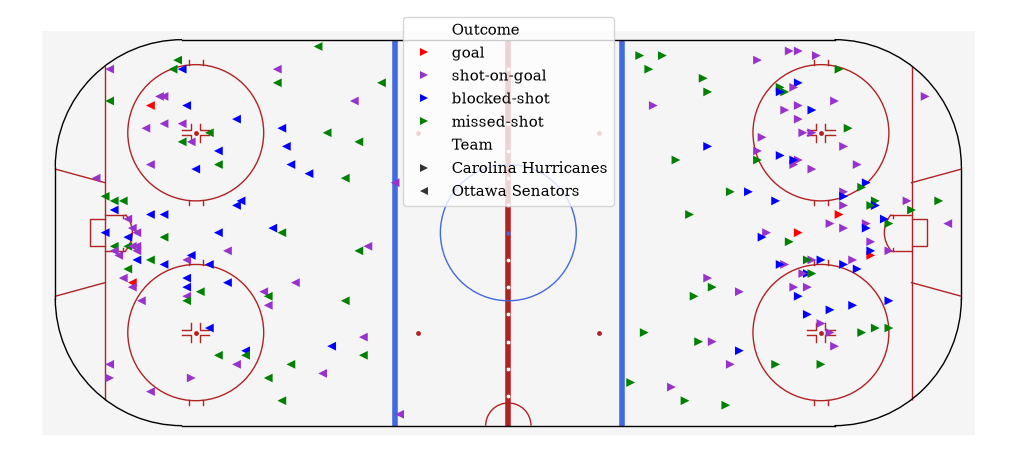

In [53]:
game = attempts[attempts['Game ID'] == idxmax].copy()
home_shot = game['Team Making the Play'] == game['Home Team']

needed = np.where(home_shot, 89, -89)
flip = goal_x(game) != needed

print('Ударов, у которых разворачиваем координаты:', flip.sum(), 'из', len(game))
print('Совпадает с правилом «нечетные периоды»:', bool((flip == (game['Period'] % 2 == 1)).all()))

game['x'] = np.where(flip, -game['X Coordinate on the Ice Rink'], game['X Coordinate on the Ice Rink'])
game['y'] = np.where(flip, -game['Y Coordinate on the Ice Rink'], game['Y Coordinate on the Ice Rink'])
game = game.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

# хозяева бьют вправо (треугольник >), гости влево (треугольник <)
markers = {game['Home Team'].iloc[0]: '>', game['Away Team'].iloc[0]: '<'}
palette = {'goal': 'red', 'shot-on-goal': 'darkorchid', 'blocked-shot': 'blue', 'missed-shot': 'green'}

plt.figure(figsize=(10, 4.5))
plot_rink()
sns.scatterplot(data=game, x='x', y='y', hue='Outcome', style='Team',
                hue_order=list(palette), palette=palette, markers=markers, s=40, linewidth=0)
plt.axis('equal')
plt.axis('off')
plt.legend(loc='upper center')
plt.tight_layout(pad=0.1)
save_figure('rink_game')
plt.show()

In [54]:
game['Distance'] = shot_length(game['x'], game['y'], np.where(home_shot, 89, -89))

print(pd.crosstab(game['Team'], game['Outcome'])[['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot']])
print()
print('Расстояние до ворот:')
print(game.groupby('Outcome')['Distance'].describe().loc[['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot']])
print()
print('Доля ударов дальше 60 футов (за синей линией): %.1f%%' % (100 * (game['Distance'] > 60).mean()))

Outcome              goal  shot-on-goal  blocked-shot  missed-shot
Team                                                              
Carolina Hurricanes     3            46            26           34
Ottawa Senators         2            37            28           32

Расстояние до ворот:
              count   mean    std   min    25%    50%    75%     max
Outcome                                                             
goal          5.000 17.435  8.247 9.220 10.000 16.031 25.000  26.926
shot-on-goal 83.000 34.036 32.229 2.236 15.888 27.803 39.121 186.000
blocked-shot 54.000 25.485 12.995 0.000 14.082 27.386 35.550  54.626
missed-shot  66.000 35.837 20.057 2.000 21.714 38.063 52.889  69.971

Доля ударов дальше 60 футов (за синей линией): 8.7%


Каролина (хозяева) бьет в правые ворота, Оттава (гости) в левые. Ударов у Каролины 109 (3 гола, 46 в створ, 26 заблокировано, 34 мимо), у Оттавы 99 (2 гола, 37 в створ, 28 заблокировано, 32 мимо), то есть команды бросали примерно одинаково, а голов всего пять на 208 ударов.

Основная масса ударов летит из зоны нападения, плотнее всего вокруг кругов вбрасывания и перед воротами. Все пять голов забиты с расстояния до 27 футов, то есть из ближней зоны. Заблокированные броски (зеленые) в основном ближние (медиана 27 футов, максимум 55), потому что дальние броски защитникам блокировать сложнее. Неточные (красные) в среднем с большего расстояния (медиана 38 футов против 28 у точных) и разбросаны шире. Дальше 60 футов всего 8,7% ударов. Среди них встречаются и странные точные удары с расстояния до 186 футов, то есть с другого конца площадки: это тот самый хвост, который мы разбирали в пункте 9.

**Пункт 16.** Голы забивает игрок из `Player in the Event #1` в событиях `goal`. Если у нескольких игроков одинаковое число голов, их порядок внутри ничьей я задаю по алфавиту.

In [55]:
goals = events[events['Play Type'] == 'goal']

def top(counts, n=10):
    counts = counts.rename_axis('Player').reset_index(name='Count')
    return counts.sort_values(['Count', 'Player'], ascending=[False, True]).head(n).reset_index(drop=True)


goal_count = goals['Player in the Event #1'].value_counts()
print(top(goal_count))
print()
print('Игроков с таким же числом голов, как у десятого места:', (goal_count == top(goal_count)['Count'].iloc[-1]).sum())

            Player  Count
0     Brett Howden     14
1  Pavel Dorofeyev     12
2  Logan Stankoven     11
3     Mitch Marner     10
4     Jordan Staal      8
5   Nikolaj Ehlers      8
6     Alex Newhook      7
7    Jackson Blake      7
8       Mark Stone      7
9       Matt Boldy      7

Игроков с таким же числом голов, как у десятого места: 6


Лучший снайпер плей-офф Brett Howden, он забил 14 шайб, дальше Pavel Dorofeyev - 12, Logan Stankoven - 11 и Mitch Marner - 10. За ними Jordan Staal и Nikolaj Ehlers по 8, а места с седьмого по десятое делят шесть игроков с 7 голами. В десятку они попали по алфавиту, так что по факту у десятого места ничья между шестью игроками. Отрыв лидера от остальных заметный: 14 голов против 12 у второго.

**Пункт 17.** Голевые передачи - это игроки из `Player in the Event #2` и `#3` в событиях `goal`.

In [56]:
assist_count = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).value_counts()
print(top(assist_count))
print()
print('Игроков с таким же числом передач, как у десятого места:', (assist_count == top(assist_count)['Count'].iloc[-1]).sum())
print('Всего голевых передач:', assist_count.sum(), ' голов:', len(goals))

            Player  Count
0      Jack Eichel     20
1     Mitch Marner     19
2    Jackson Blake     13
3      Lane Hutson     13
4     Martin Necas     12
5      Nick Suzuki     12
6    Shea Theodore     12
7      Taylor Hall     12
8  Kirill Kaprizov     11
9     Quinn Hughes     11

Игроков с таким же числом передач, как у десятого места: 2
Всего голевых передач: 830  голов: 486


Больше всего голевых передач у Jack Eichel - 20 и Mitch Marner - 19, дальше с отрывом Jackson Blake и Lane Hutson - по 13. Ничьи на десятом месте нет, так что десятка однозначная. Всего в плей-офф было 486 голов и 830 передач, то есть на гол в среднем 1,7 передачи (максимум две). У лидеров по передачам почти нет своих голов, например, у Eichel всего 2

**Пункт 18.** Очки это голы плюс передачи. Игроки, у которых нет голов или нет передач, не должны пропасть, поэтому складываем с `fill_value=0`

In [57]:
points = goal_count.add(assist_count, fill_value=0).astype(int)

table = pd.DataFrame({'Goals': goal_count, 'Assists': assist_count, 'Points': points}).fillna(0).astype(int)
table = table.rename_axis('Player').reset_index().sort_values(['Points', 'Goals', 'Player'], ascending=[False, False, True])
print(table.head(10).reset_index(drop=True))
print()
print('Игроков с таким же числом очков, как у десятого места:', (table['Points'] == table['Points'].iloc[9]).sum())

            Player  Goals  Assists  Points
0     Mitch Marner     10       19      29
1      Jack Eichel      2       20      22
2    Jackson Blake      7       13      20
3      Taylor Hall      7       12      19
4     Brett Howden     14        4      18
5   Nikolaj Ehlers      8       10      18
6    Shea Theodore      6       12      18
7  Pavel Dorofeyev     12        4      16
8  Logan Stankoven     11        5      16
9      Nick Suzuki      4       12      16

Игроков с таким же числом очков, как у десятого места: 4


Лидер по очкам Mitch Marner, 29 (10 голов и 19 передач), он - единственный в десятке, у кого и голов, и передач не меньше десяти. На втором месте Jack Eichel, 22 очка, но почти все они за счет передач (2 гола и 20 передач). Brett Howden, лучший снайпер, с 14 голами оказался только пятым, так как у него всего 4 передачи. В десятке в основном те, чьи команды дошли далеко и сыграли много матчей. На 16 очках у десятого места ничья между четырьмя игроками, порядок внутри ничьей задан числом голов

**Пункт 19.** «В среднем за одну игру» - это число бросков, деленное на число игр, в которых игрок участвовал. Число игр в таблице `players` из пункта 7. Броски в створ - это `shot-on-goal` и `goal`, бросавший это `Player in the Event #1`.

In [58]:
games_of_player = players.groupby('Player').size().rename('Games')

shots_on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts().rename('Shots')

shots_table = pd.concat([shots_on_goal, games_of_player], axis=1, join='inner')
shots_table['Shots per Game'] = shots_table['Shots'] / shots_table['Games']
shots_table = shots_table.rename_axis('Player').reset_index()

print(shots_table.sort_values(['Shots per Game', 'Player'], ascending=[False, True]).head(10).reset_index(drop=True))
print()
print('Игроков в плей-офф:', len(games_of_player), ' медиана числа игр:', games_of_player.median())

             Player  Shots  Games  Shots per Game
0   Jason Robertson     30      6           5.000
1    Dylan Guenther     27      6           4.500
2   Nikita Kucherov     31      7           4.429
3        Matt Boldy     48     11           4.364
4   Quinton Byfield     17      4           4.250
5    Darren Raddysh     28      7           4.000
6  Joel Eriksson Ek     24      6           4.000
7   Alex Laferriere     15      4           3.750
8    David Pastrnak     22      6           3.667
9  Nathan MacKinnon     47     13           3.615

Игроков в плей-офф: 372  медиана числа игр: 6.0


Лидер - Jason Robertson, 5 бросков в створ за игру (30 за 6 игр), за ним Dylan Guenther (4,5), Nikita Kucherov (4,4) и Matt Boldy (4,4 за 11 игр). В список попали игроки, сыгравшие всего по 4 игры (Quinton Byfield, Alex Laferriere), а в среднем за четыре игры один матч с большим числом бросков сильно двигает результат. Поэтому ниже тот же рейтинг для игроков, сыгравших не меньше 6 игр: он почти такой же, но без маленьких выборок. Самый устойчивый результат у Nathan MacKinnon, Alex Tuch и Rasmus Dahlin: около 3,5 броска за игру на дистанции в 13 игр

In [59]:
print('Только игроки, сыгравшие не меньше 6 игр:')
print(shots_table[shots_table['Games'] >= 6].sort_values(['Shots per Game', 'Player'], ascending=[False, True])
      .head(10).reset_index(drop=True))

Только игроки, сыгравшие не меньше 6 игр:
             Player  Shots  Games  Shots per Game
0   Jason Robertson     30      6           5.000
1    Dylan Guenther     27      6           4.500
2   Nikita Kucherov     31      7           4.429
3        Matt Boldy     48     11           4.364
4    Darren Raddysh     28      7           4.000
5  Joel Eriksson Ek     24      6           4.000
6    David Pastrnak     22      6           3.667
7  Nathan MacKinnon     47     13           3.615
8         Alex Tuch     46     13           3.538
9     Rasmus Dahlin     46     13           3.538


**Пункт 20.** То же самое для силовых приемов (`hit`), тот, кто делает прием, это `Player in the Event #1`.

In [60]:
hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts().rename('Hits')

hits_table = pd.concat([hits, games_of_player], axis=1, join='inner')
hits_table['Hits per Game'] = hits_table['Hits'] / hits_table['Games']
hits_table = hits_table.rename_axis('Player').reset_index()

print(hits_table.sort_values(['Hits per Game', 'Player'], ascending=[False, True]).head(10).reset_index(drop=True))
print()
print('Только игроки, сыгравшие не меньше 6 игр:')
print(hits_table[hits_table['Games'] >= 6].sort_values(['Hits per Game', 'Player'], ascending=[False, True])
      .head(10).reset_index(drop=True))

               Player  Hits  Games  Hits per Game
0       Lawson Crouse    38      6          6.333
1       Alex Turcotte     6      1          6.000
2  Alexander Petrovic     6      1          6.000
3        Yakov Trenin    51      9          5.667
4        Dylan Cozens    22      4          5.500
5    Vasily Podkolzin    32      6          5.333
6     Carl Grundstrom    15      3          5.000
7      Ivan Barbashev   110     22          5.000
8      Marcus Foligno    55     11          5.000
9        Owen Tippett    29      6          4.833

Только игроки, сыгравшие не меньше 6 игр:
             Player  Hits  Games  Hits per Game
0     Lawson Crouse    38      6          6.333
1      Yakov Trenin    51      9          5.667
2  Vasily Podkolzin    32      6          5.333
3    Ivan Barbashev   110     22          5.000
4    Marcus Foligno    55     11          5.000
5      Owen Tippett    29      6          4.833
6   William Carrier    91     19          4.789
7        Cole Smith   1

Лидер - Lawson Crouse, 6,3 приема за игру (38 за 6 игр). Дальше Alex Turcotte и Alexander Petrovic с 6 приемами за игру, но у обоих всего одна игра, и это - шум. После фильтра по числу игр список выглядит осмысленнее: Crouse, Yakov Trenin (5,7), Vasily Podkolzin (5,3), Ivan Barbashev (5,0) и Marcus Foligno (5,0). Самый надежный результат у Barbashev: 110 приемов за 22 игры

**Пункт 21.** Для каждого гола смотрим, кто был вратарем у команды, пропустившей гол: если гол забили хозяева, это `Away Team's Goalie`, и наоборот. Состав берем из таблицы `state` (то есть до гола), иначе гол запишется вратарю, который вышел на замену сразу после него, а у голов овертайма вообще не будет вратаря.

Если вратаря в составе нет (ворота пустые), то гол идет на счет последнего вратаря этой команды в игре, то есть того, которого сняли ради шестого полевого игрока.

Потом берем все пары «игра, вратарь», в которых вратарь хотя бы раз был на льду, и оставляем те, где за время его пребывания в воротах не было пропущено ни одного гола. Вратарь, который вышел на замену на последние минуты, тоже попадет в список

In [61]:
away_g = "Away Team's Goalie"
home_g = "Home Team's Goalie"

goals = events[events['Play Type'] == 'goal'].copy()
others = events[events['Play Type'] != 'goal']

last_known = (others.groupby('Game ID')[[away_g, home_g]].ffill()
                    .reindex(events.index).groupby(events['Game ID']).ffill())
goals['Goalie'] = np.where(goals['Team Making the Play'] == goals['Home Team'],
                           last_known.loc[goals.index, away_g], last_known.loc[goals.index, home_g])

own_row = np.where(goals['Team Making the Play'] == goals['Home Team'],
                   goals[away_g], goals[home_g])
print('Голов, которые остались без вратаря:', goals['Goalie'].isna().sum())
print('Голов, где вратарь «после гола» отличается от вратаря «до гола»:',
      (pd.Series(own_row, index=goals.index).notna() & (pd.Series(own_row, index=goals.index) != goals['Goalie'])).sum())

conceded = goals.groupby(['Game ID', 'Goalie']).size().rename('Conceded')

appearances = (pd.concat([events[['Game ID', away_g]].set_axis(['Game ID', 'Goalie'], axis=1).assign(Side='Away'),
                          events[['Game ID', home_g]].set_axis(['Game ID', 'Goalie'], axis=1).assign(Side='Home')])
                 .dropna().drop_duplicates(['Game ID', 'Goalie']).set_index(['Game ID', 'Goalie']))
appearances['Conceded'] = conceded.reindex(appearances.index).fillna(0).astype(int)

ids = appearances.index.get_level_values('Game ID')
appearances['Team Conceded'] = np.where(appearances['Side'] == 'Away', games.loc[ids, 'Home Score'].values,
                                        games.loc[ids, 'Away Score'].values)

print('Пропущенных голов в таблице:', appearances['Conceded'].sum(), ' всего голов:', len(goals))

shutouts = appearances[appearances['Conceded'] == 0].reset_index()
shutouts['Game'] = shutouts['Game ID'].map(gameInfo)
shutouts['Whole game'] = shutouts['Team Conceded'] == 0

print('Пар «игра, вратарь»:', len(appearances), ' из них без пропущенных голов:', len(shutouts))
print()
print(shutouts.groupby('Goalie').size().sort_values(ascending=False).rename('Games without goals against'))

Голов, которые остались без вратаря: 0
Голов, где вратарь «после гола» отличается от вратаря «до гола»: 5
Пропущенных голов в таблице: 486  всего голов: 486
Пар «игра, вратарь»: 174  из них без пропущенных голов: 11

Goalie
Frederik Andersen       3
Dan Vladar              2
Alex Lyon               1
Andrei Vasilevskiy      1
Brandon Bussi           1
Joonas Korpisalo        1
Scott Wedgewood         1
Ukko-Pekka Luukkonen    1
Name: Games without goals against, dtype: int64


In [62]:
print(shutouts[['Goalie', 'Game', 'Whole game']].sort_values(['Goalie', 'Game']).to_string(index=False))
print()
print('Команда ничего не пропустила за всю игру:', shutouts['Whole game'].sum(), ' вратарь вышел на замену или был заменен:', (~shutouts['Whole game']).sum())

              Goalie                                                                    Game  Whole game
           Alex Lyon               Buffalo Sabres - Boston Bruins (2 - 4, Final, 2026-04-21)       False
  Andrei Vasilevskiy  Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)        True
       Brandon Bussi   Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)        True
          Dan Vladar Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)        True
          Dan Vladar    Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)        True
   Frederik Andersen        Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)        True
   Frederik Andersen    Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)        True
   Frederik Andersen     Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)        True
    Joonas Korpisalo               Boston Bruins - Buff

Всего 11 пар «игра, вратарь», в которых вратарь не пропустил ни одного гола, у восьми вратарей. Больше всех у Frederik Andersen, три игры (2-0 с Оттавой, 3-0 с Филадельфией, 4-0 с Монреалем), по две у Dan Vladar. В семи из этих игр команда за весь матч ничего не пропустила, а в четырех вратарь вышел на замену и сам голов не пропустил (Lyon, Luukkonen, Korpisalo, Wedgewood): в этих матчах команда голы пропускала, но уже при другом вратаре.

Если бы мы не заметили, что в записях `goal` состав показан после гола, список получился бы другим. В него по ошибке попали бы Arturs Silovs и Jakub Dobes, вратари, чьи команды проиграли 0-1 в овертайме (решающий гол записан без игроков на льду). А Lyon и Luukkonen из списка пропали бы, потому что гол, после которого их выпустили, записан уже на них.

**Пункт 22.** Вопрос: кто чаще всех нарушал правила? Топ-10 игроков и топ-10 команд по числу удалений.

Удаление это событие `penalty`. Отложенные удаления (`delayed-penalty`) не считаем,так как это - не считается удалением. В `penalty` нарушитель это `Player in the Event #1`, а `Team Making the Play` это команда нарушителя. У части удалений игрока нет (например, лишний игрок на льду или нарушение скамейки), они учитываются только в командном рейтинге.

Команды сыграли очень разное число игр (от 4 до 22), поэтому для команд надо показать и общее число удалений, и число на одну игру.

In [63]:
penalties = events[events['Play Type'] == 'penalty']
print('Удалений всего:', len(penalties), ' из них без указанного игрока:', penalties['Player in the Event #1'].isna().sum())

by_player = (penalties.dropna(subset=['Player in the Event #1']).groupby('Player in the Event #1')
             .agg(Team=('Team Making the Play', 'first'), Penalties=('Play Type', 'size'))
             .rename_axis('Player').reset_index()
             .sort_values(['Penalties', 'Player'], ascending=[False, True]).reset_index(drop=True))

print(by_player.head(10))
print()
print('Игроков с таким же числом удалений, как у десятого места:', (by_player['Penalties'] == by_player['Penalties'].iloc[9]).sum())

Удалений всего: 804  из них без указанного игрока: 30
              Player                  Team  Penalties
0       Kaiden Guhle    Montréal Canadiens         14
1  Andrei Svechnikov   Carolina Hurricanes         12
2        Zach Benson        Buffalo Sabres         12
3         Cole Smith  Vegas Golden Knights         11
4      Josh Anderson    Montréal Canadiens         11
5      Rasmus Dahlin        Buffalo Sabres         11
6       Arber Xhekaj    Montréal Canadiens         10
7      Mike Matheson    Montréal Canadiens          9
8     Nikita Zadorov         Boston Bruins          9
9   Rasmus Andersson  Vegas Golden Knights          9

Игроков с таким же числом удалений, как у десятого места: 5


In [64]:
by_team = penalties.groupby('Team Making the Play').size().rename('Penalties').to_frame()
by_team['Games'] = games_played
by_team['Penalties per Game'] = by_team['Penalties'] / by_team['Games']

print('По общему числу удалений:')
print(by_team.sort_values('Penalties', ascending=False).head(10))
print()
print('По числу удалений за игру:')
print(by_team.sort_values('Penalties per Game', ascending=False).head(10))
print()
print('Меньше всего удалений за игру:')
print(by_team.sort_values('Penalties per Game').head(3))

По общему числу удалений:
                      Penalties  Games  Penalties per Game
Team Making the Play                                      
Montréal Canadiens          111     19               5.842
Carolina Hurricanes          94     19               4.947
Vegas Golden Knights         79     22               3.591
Buffalo Sabres               75     13               5.769
Philadelphia Flyers          71     10               7.100
Colorado Avalanche           50     13               3.846
Minnesota Wild               49     11               4.455
Tampa Bay Lightning          42      7               6.000
Boston Bruins                41      6               6.833
Pittsburgh Penguins          37      6               6.167

По числу удалений за игру:
                      Penalties  Games  Penalties per Game
Team Making the Play                                      
Philadelphia Flyers          71     10               7.100
Boston Bruins                41      6               6.833
Pi

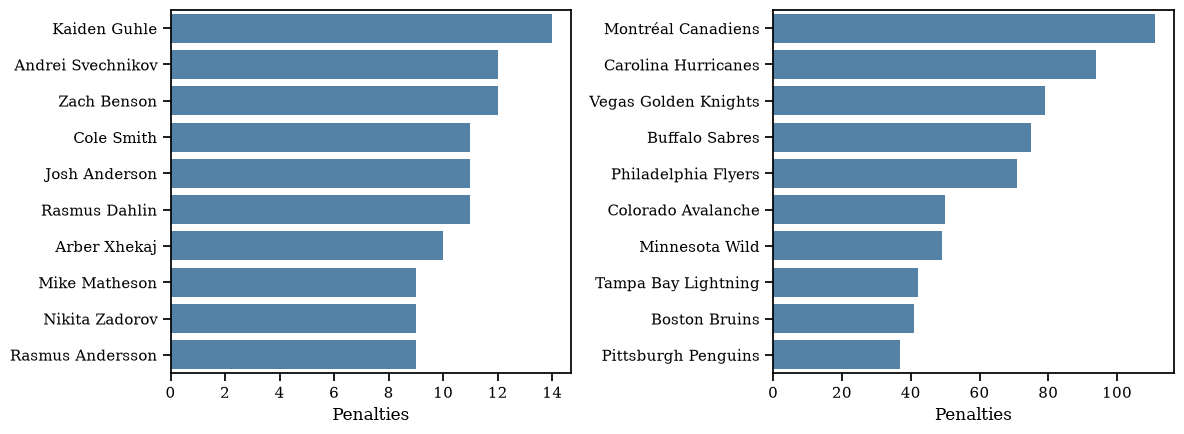

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=by_player.head(10), y='Player', x='Penalties', color='steelblue', ax=axes[0])
axes[0].set_xlabel('Penalties')
axes[0].set_ylabel('')
top_teams = by_team.sort_values('Penalties', ascending=False).head(10).reset_index()
sns.barplot(data=top_teams, y='Team Making the Play', x='Penalties', color='steelblue', ax=axes[1])
axes[1].set_xlabel('Penalties')
axes[1].set_ylabel('')
plt.tight_layout()
save_figure('penalties')
plt.show()

**Игроки.** Больше всех удалений у Kaiden Guhle из Монреаля, 14. Дальше Andrei Svechnikov (Каролина) и Zach Benson (Баффало) по 12, затем Cole Smith (Вегас), Josh Anderson (Монреаль) и Rasmus Dahlin (Баффало) по 11. В десятке четыре игрока Монреаля (Guhle, Anderson, Xhekaj и Matheson), по два у Баффало и Вегаса. На девяти удалениях у десятого места ничья между пятью игроками, в десятку три из них попали по алфавиту (Matheson, Zadorov, Andersson), а Hartman и Konecny остались за чертой.

**Команды по общему числу.** Больше всех у Монреаля, 111 удалений, затем Каролина (94), Вегас (79), Баффало (75) и Филадельфия (71). Но этот рейтинг в основном отражает число сыгранных игр: Монреаль и Каролина сыграли по 19 игр, Вегас 22, а Филадельфия только 10.

**Команды по числу за игру.** С поправкой на число игр картина другая: больше всех нарушала Филадельфия (7,1 удаления за игру), затем Бостон (6,8), Питтсбург (6,2), Тампа (6,0) и Монреаль (5,8). Меньше всех Анахайм (3,0), Эдмонтон (3,3) и Вегас (3,6). Вегас сыграл больше всех игр, но нарушал реже большинства, а у Бостона и Питтсбурга всего по шесть игр, поэтому их места в рейтинге менее надежны. В среднем в игре было около 9,8 удаления на обе команды, то есть почти 5 на команду.

Итог: чаще всех нарушали Guhle среди игроков и Монреаль по общему числу удалений, а по числу за игру Филадельфия.